In [40]:
import os, operator
from typing import List, Annotated, Dict
from typing_extensions import TypedDict

from openai import OpenAI
from langchain_openai import ChatOpenAI
from langchain_core.messages import (
    SystemMessage,
    HumanMessage,
    AIMessage,
    BaseMessage,
)
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, END
from langgraph.checkpoint.memory import MemorySaver
from pydantic import BaseModel, Field

from IPython.display import Image, display, Markdown

In [41]:
from langchain_groq import ChatGroq

llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0)

In [42]:
class State(TypedDict):
    idea: str
    messages: Annotated[List[BaseMessage], add_messages]
    advisor_reports: Annotated[Dict[str, str], operator.or_]
    final_report: str

In [43]:
base_system_msg = SystemMessage(
    content=(
        """
        You are a helpful tool
        Your job: decide whether you have enough information about the start-up idea.
        If not, ask ONE precise follow-up question.
        If yes, say: DONE
        """
    )
)

In [44]:
def decide_node(state: State):
    conversation = [base_system_msg] + state["messages"]
    ai_reply: AIMessage = llm.invoke(conversation)
    return {"messages": [ai_reply]}

In [45]:
def route(state: State):
    last_ai_msg: AIMessage = state["messages"][-1]
    if last_ai_msg.content.strip().upper().startswith("DONE"):
        return "fanout"
    return "ask_user_node"

In [46]:
def ask_user_node(state: State):
    question = state["messages"][-1].content
    print(f"\nAssistant: {question}\n")
    human = input("You: ")
    new_messages = state["messages"] + [HumanMessage(content=human)]
    
    return {"messages": new_messages,
            "human_advisor_feedback": human,}

In [47]:
def market_analyst_advisor(state: State):
    prompt = f"""
    You are a helpfull senior MARKET ANALYST that gets an idea as an input. You need to Evaluate the market potential, competition, target demographics, and timing.
    Conduct market sizing and competitor research
    Identify target customers and segments
    Assess timing, trends, and macroeconomic influences
    Idea:
    {state['messages']}
    """
    report = llm.invoke([SystemMessage(content=prompt)])
    return {"advisor_reports": {"Market Analyst": report.content}}

In [48]:
def legal_advisor(state: State):
    prompt = f"""
    You are a helpfull Legal Advisor that gets an idea as an input. You need to:
    Identify IP, licensing, and trademark needs
    Spot compliance issues (e.g., GDPR, financial regulations)
    Evaluate contract and partnership considerations
    Idea:
    {state['messages']}
    """
    report = llm.invoke([SystemMessage(content=prompt)])
    return {"advisor_reports": {"Legal Advisor": report.content}}

In [49]:
def technical_advisor(state: State):
    prompt = f"""
    You are a helpfull Technical/Product Feasibility Expert that gets an idea as an input. You need to:
    Estimate development complexity and time
    Recommend tech stacks or platforms
    Evaluate risk in terms of infrastructure, scalability, and cost
    Idea:
    {state['messages']}
    """
    report = llm.invoke([SystemMessage(content=prompt)])
    return {"advisor_reports": {"Technical Advisor": report.content}}

In [50]:
def strategist_advisor(state: State):
    prompt = f"""
    You are a helpful Business Strategist that gets an idea as an input. You need to:
    Assess business model viability and revenue streams
    Identify competitive advantages and strategic positioning
    Highlight key risks, scaling opportunities, and go-to-market strategy
    Idea:
    {state['messages']}
    """
    report = llm.invoke([SystemMessage(content=prompt)])
    return {"advisor_reports": {"Business Strategist": report.content}}

In [51]:
def collect_and_report(state: State):
    if len(state["advisor_reports"]) < 4:
        return {}
    report_prompt = f"""
    You are a senior consultant. Combine the four advisor notes below into one clear, structured evaluation report for the founder.
    {state['advisor_reports']}
    """
    report = llm.invoke(report_prompt).content
    display(Markdown("### FINAL REPORT\n\n" + report))
    return {"final_report": report}

In [55]:
builder = StateGraph(State)

builder.add_node("decide_node", decide_node)
builder.add_node("ask_user_node", ask_user_node)
builder.add_node("fanout", lambda state: {}) # does nothing - just a hub
builder.add_node("market_analyst_advisor", market_analyst_advisor)
builder.add_node("legal_advisor", legal_advisor)
builder.add_node("technical_advisor", technical_advisor)
builder.add_node("strategist_advisor", strategist_advisor)
builder.add_node("collect_and_report", collect_and_report)

In [56]:
builder.set_entry_point("decide_node")
builder.add_edge("ask_user_node", "decide_node")
builder.add_conditional_edges(
    "decide_node", route, {"ask_user_node": "ask_user_node", "fanout": "fanout"}
)
builder.add_edge("fanout", "market_analyst_advisor")
builder.add_edge("fanout", "legal_advisor")
builder.add_edge("fanout", "technical_advisor")
builder.add_edge("fanout", "strategist_advisor")

builder.add_edge("market_analyst_advisor", "collect_and_report")
builder.add_edge("legal_advisor", "collect_and_report")
builder.add_edge("technical_advisor", "collect_and_report")
builder.add_edge("strategist_advisor", "collect_and_report")

builder.add_edge("collect_and_report", END)

graph = builder.compile()

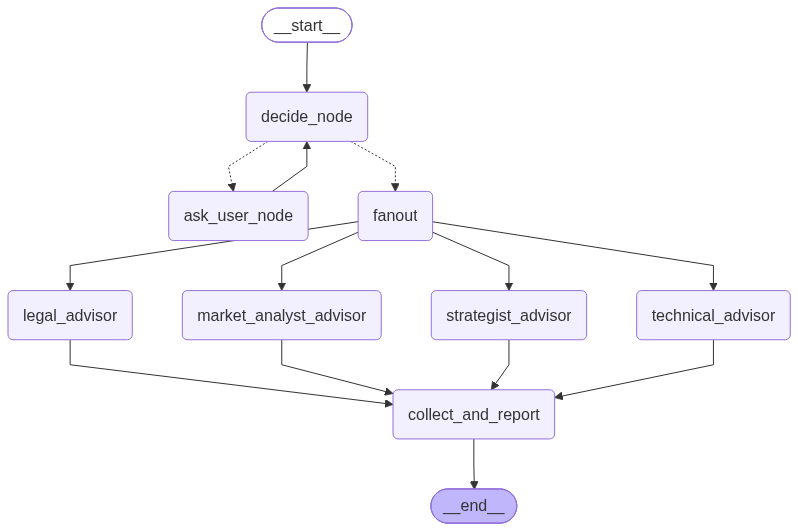

In [57]:
display(Image(graph.get_graph(xray=1).draw_mermaid_png()))


In [58]:
print("What is your business idea?")
idea = input("You: ")

init_state: State = {
    "idea": idea,
    "messages": [HumanMessage(content=idea)],
    "advisor_reports": {},
    "final_report": "",
}

graph.invoke(init_state, config={"configurable": {"thread_id": "run-1"}});

What is your business idea?


You:  My idea is to sell handmade bamboo toothbrushes



Assistant: Who is your target market for the handmade bamboo toothbrushes?



You:  My target is eco-conscious adults, between 20 and 35,who are looking for affordable sustainable alternatives to plastic products.



Assistant: What sales channels do you plan to use to reach these eco‑conscious adults (e.g., online store, retail partners, subscription model, etc.)?



You:  Online store through our website and Instagram page, plus local eco-friendly stores.



Assistant: What price do you plan to charge for each toothbrush, and what profit margin are you targeting per unit?



You:  We plan to retail each toothbrush for $5, targeting a 60% profit margin per unit.



Assistant: What is your estimated cost to produce each bamboo toothbrush (including materials, labor, packaging, and shipping) so we can confirm the 60 % profit margin?



You:  Production cost is $2 per toothbrush (including materials, labor, packaging, and shipping). Monthly operating expenses are $1,000 covering online marketing and website maintenance, with an initial startup capital of $2,000.


RateLimitError: Error code: 429 - {'error': {'message': 'Rate limit reached for model `openai/gpt-oss-120b` in organization `org_01m78rz285eqct1j6a71xr9vx5` service tier `on_demand` on tokens per minute (TPM): Limit 8000, Used 5277, Requested 5074. Please try again in 17.6325s. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}